In [1]:
import re
import pandas as pd

In [2]:
f=open('WhatsApp Chat with Akanksha Devi.txt','r',encoding='utf-8')

In [3]:
data=f.read()

In [4]:
print(data)

10/25/24, 12:17 PM - Messages and calls are end-to-end encrypted. Only people in this chat can read, listen to, or share them. *Learn more*
7/11/26, 12:50 PM - Nikita: <Media omitted>
7/11/26, 12:50 PM - Akanksha Devi: Thanks
7/11/26, 12:50 PM - Nikita: Welciii
7/13/26, 12:52 PM - Akanksha Devi: Arey did you ask Di to be in our group ?
7/13/26, 12:52 PM - Nikita: Yes
7/13/26, 11:09 PM - Akanksha Devi: Bhai, woh solid works ka konsa version download karna hai ?
7/13/26, 11:18 PM - Nikita: Latest
7/13/26, 11:20 PM - Nikita: Anmol bhaiya mana kar rhe hai
7/13/26, 11:20 PM - Nikita: Sunna
7/13/26, 11:20 PM - Akanksha Devi: 2026 wala version na ?
7/13/26, 11:20 PM - Akanksha Devi: Madhu Di ?
7/13/26, 11:20 PM - Nikita: Hn
7/13/26, 11:20 PM - Nikita: Yes
7/13/26, 11:20 PM - Akanksha Devi: Woh kya boli ?
7/13/26, 11:20 PM - Nikita: Rely nhi di abhi tak
7/13/26, 11:21 PM - Akanksha Devi: Ohh..
7/13/26, 11:21 PM - Akanksha Devi: Bata
7/13/26, 11:21 PM - Nikita: Team Nova kese hia
7/13/26, 11:21

In [5]:
print(type(data))

<class 'str'>


In [6]:
pattern = r'\d{1,2}/\d{1,2}/\d{2,4},\s*\d{1,2}:\d{2}\s*[AP]M\s*-\s*'

In [7]:
messages=re.split(pattern,data)

messages = [msg.strip() for msg in messages if msg.strip()]

print(messages)

['Messages and calls are end-to-end encrypted. Only people in this chat can read, listen to, or share them. *Learn more*', 'Nikita: <Media omitted>', 'Akanksha Devi: Thanks', 'Nikita: Welciii', 'Akanksha Devi: Arey did you ask Di to be in our group ?', 'Nikita: Yes', 'Akanksha Devi: Bhai, woh solid works ka konsa version download karna hai ?', 'Nikita: Latest', 'Nikita: Anmol bhaiya mana kar rhe hai', 'Nikita: Sunna', 'Akanksha Devi: 2026 wala version na ?', 'Akanksha Devi: Madhu Di ?', 'Nikita: Hn', 'Nikita: Yes', 'Akanksha Devi: Woh kya boli ?', 'Nikita: Rely nhi di abhi tak', 'Akanksha Devi: Ohh..', 'Akanksha Devi: Bata', 'Nikita: Team Nova kese hia', 'Akanksha Devi: Achaa hai', 'Nikita: I think I should write in the group', 'Nikita: Nhi lagata woh aaj dekhegi', 'Nikita: Bohot der ho gya', 'Akanksha Devi: Shayad so gayi hain...', 'Nikita: Hn', 'Nikita: Likh du ?', 'Akanksha Devi: Haan', 'Akanksha Devi: Hello bhai', 'Akanksha Devi: Kal jaake discuss karein project ke baarein main ?..

In [8]:
dates=re.findall(pattern,data)
dates = [date.replace('\u202f', ' ') for date in dates]

dates = [date.replace(' - ', '').replace('\u202f', ' ').strip()
         for date in dates]
dates

['10/25/24, 12:17 PM',
 '7/11/26, 12:50 PM',
 '7/11/26, 12:50 PM',
 '7/11/26, 12:50 PM',
 '7/13/26, 12:52 PM',
 '7/13/26, 12:52 PM',
 '7/13/26, 11:09 PM',
 '7/13/26, 11:18 PM',
 '7/13/26, 11:20 PM',
 '7/13/26, 11:20 PM',
 '7/13/26, 11:20 PM',
 '7/13/26, 11:20 PM',
 '7/13/26, 11:20 PM',
 '7/13/26, 11:20 PM',
 '7/13/26, 11:20 PM',
 '7/13/26, 11:20 PM',
 '7/13/26, 11:21 PM',
 '7/13/26, 11:21 PM',
 '7/13/26, 11:21 PM',
 '7/13/26, 11:21 PM',
 '7/13/26, 11:23 PM',
 '7/13/26, 11:23 PM',
 '7/13/26, 11:23 PM',
 '7/13/26, 11:23 PM',
 '7/13/26, 11:23 PM',
 '7/13/26, 11:23 PM',
 '7/13/26, 11:23 PM',
 '7/19/26, 7:54 PM',
 '7/19/26, 7:54 PM',
 '7/19/26, 7:54 PM',
 '7/19/26, 7:54 PM',
 '7/19/26, 7:55 PM',
 '7/19/26, 7:55 PM',
 '7/19/26, 7:55 PM',
 '7/19/26, 7:55 PM',
 '7/19/26, 7:56 PM',
 '7/19/26, 7:56 PM',
 '7/21/26, 11:40 AM',
 '7/21/26, 11:41 AM',
 '7/21/26, 11:41 AM',
 '7/21/26, 11:47 AM',
 '7/21/26, 11:47 AM',
 '7/21/26, 3:06 PM',
 '7/21/26, 3:22 PM',
 '7/22/26, 11:45 AM',
 '7/22/26, 11:45 AM',

In [9]:
df=pd.DataFrame({'user_message':messages,'message_date':dates})


# Convert message_date to datetime
df['message_date'] = pd.to_datetime(
    df['message_date'],
    format='%m/%d/%y, %I:%M %p'
)

# Rename column
df.rename(columns={'message_date':'date'},inplace=True)

df.head()



,user_message,date
0,Messages and calls are end-to-end encrypted. O...,2024-10-25 12:17:00
1,Nikita: <Media omitted>,2026-07-11 12:50:00
2,Akanksha Devi: Thanks,2026-07-11 12:50:00
3,Nikita: Welciii,2026-07-11 12:50:00
4,Akanksha Devi: Arey did you ask Di to be in ou...,2026-07-13 12:52:00


In [10]:
df.shape

(348, 2)

In [11]:
# separate users and messages
users=[]
messages=[]
for message in df['user_message']:
    entry=re.split('([\w\W]+?):\s',message)
    if entry[1:] : #user name
        users.append(entry[1])
        messages.append(entry[2])
    else:
        users.append('group_notification')
        messages.append(entry[0])
df['user']=users
df['message']=messages
df.drop(columns=['user_message'],inplace=True)

df.head()

<>:5: SyntaxWarning: invalid escape sequence '\w'
<>:5: SyntaxWarning: invalid escape sequence '\w'
C:\Users\niwas\AppData\Local\Temp\ipykernel_11212\2115798796.py:5: SyntaxWarning: invalid escape sequence '\w'
  entry=re.split('([\w\W]+?):\s',message)


,date,user,message
0,2024-10-25 12:17:00,group_notification,Messages and calls are end-to-end encrypted. O...
1,2026-07-11 12:50:00,Nikita,<Media omitted>
2,2026-07-11 12:50:00,Akanksha Devi,Thanks
3,2026-07-11 12:50:00,Nikita,Welciii
4,2026-07-13 12:52:00,Akanksha Devi,Arey did you ask Di to be in our group ?


In [12]:
df['year']=df['date'].dt.year
df.head()


,date,user,message,year
0,2024-10-25 12:17:00,group_notification,Messages and calls are end-to-end encrypted. O...,2024
1,2026-07-11 12:50:00,Nikita,<Media omitted>,2026
2,2026-07-11 12:50:00,Akanksha Devi,Thanks,2026
3,2026-07-11 12:50:00,Nikita,Welciii,2026
4,2026-07-13 12:52:00,Akanksha Devi,Arey did you ask Di to be in our group ?,2026


In [13]:
df['month']=df['date'].dt.month_name()
df.head()

,date,user,message,year,month
0,2024-10-25 12:17:00,group_notification,Messages and calls are end-to-end encrypted. O...,2024,October
1,2026-07-11 12:50:00,Nikita,<Media omitted>,2026,July
2,2026-07-11 12:50:00,Akanksha Devi,Thanks,2026,July
3,2026-07-11 12:50:00,Nikita,Welciii,2026,July
4,2026-07-13 12:52:00,Akanksha Devi,Arey did you ask Di to be in our group ?,2026,July


In [14]:
df['day']=df['date'].dt.day
df.head()

,date,user,message,year,month,day
0,2024-10-25 12:17:00,group_notification,Messages and calls are end-to-end encrypted. O...,2024,October,25
1,2026-07-11 12:50:00,Nikita,<Media omitted>,2026,July,11
2,2026-07-11 12:50:00,Akanksha Devi,Thanks,2026,July,11
3,2026-07-11 12:50:00,Nikita,Welciii,2026,July,11
4,2026-07-13 12:52:00,Akanksha Devi,Arey did you ask Di to be in our group ?,2026,July,13


In [15]:
df['hour']=df['date'].dt.hour

In [16]:
df['minute']=df['date'].dt.minute

In [17]:
df.head()

,date,user,message,year,month,day,hour,minute
0,2024-10-25 12:17:00,group_notification,Messages and calls are end-to-end encrypted. O...,2024,October,25,12,17
1,2026-07-11 12:50:00,Nikita,<Media omitted>,2026,July,11,12,50
2,2026-07-11 12:50:00,Akanksha Devi,Thanks,2026,July,11,12,50
3,2026-07-11 12:50:00,Nikita,Welciii,2026,July,11,12,50
4,2026-07-13 12:52:00,Akanksha Devi,Arey did you ask Di to be in our group ?,2026,July,13,12,52


In [18]:
df[df['user']=='Nikita'].shape

(156, 8)

In [19]:
words=[]
for message in df['message']:
    words.extend(message.split())

In [20]:
len(words)

1306

In [21]:
from urlextract import URLExtract


extractor=URLExtract()
urls=extractor.find_urls("Let's www.gmail.com have URL stackoverflow.com as an example google.com , http://facebook.com , ftp://url.in .")
urls

['www.gmail.com',
 'stackoverflow.com',
 'google.com',
 'http://facebook.com',
 'ftp://url.in']

In [22]:
y=[]
for message in df['message']:
    y.extend(extractor.find_urls(message))



In [23]:
len(y)
    

1

In [24]:
y

['https://colab.research.google.com/drive/1uFLdePBP1OzIBdl_wOV1LXkgoAxA9pV4?usp=sharing']

In [25]:
df

,date,user,message,year,month,day,hour,minute
0,2024-10-25 12:17:00,group_notification,Messages and calls are end-to-end encrypted. O...,2024,October,25,12,17
1,2026-07-11 12:50:00,Nikita,<Media omitted>,2026,July,11,12,50
2,2026-07-11 12:50:00,Akanksha Devi,Thanks,2026,July,11,12,50
3,2026-07-11 12:50:00,Nikita,Welciii,2026,July,11,12,50
4,2026-07-13 12:52:00,Akanksha Devi,Arey did you ask Di to be in our group ?,2026,July,13,12,52
...,...,...,...,...,...,...,...,...
343,2026-10-10 11:08:00,Nikita,Sunnnnn,2026,October,10,11,8
344,2026-10-10 11:08:00,Nikita,Aaj jaldi aana class,2026,October,10,11,8
345,2026-10-10 12:12:00,Akanksha Devi,Okayh,2026,October,10,12,12
346,2026-10-11 13:04:00,Akanksha Devi,😂,2026,October,11,13,4


In [26]:
x=df['user'].value_counts().head()

In [27]:
import matplotlib.pyplot as plt


In [28]:
name=x.index
count=x.values

<function matplotlib.pyplot.show(close=None, block=None)>

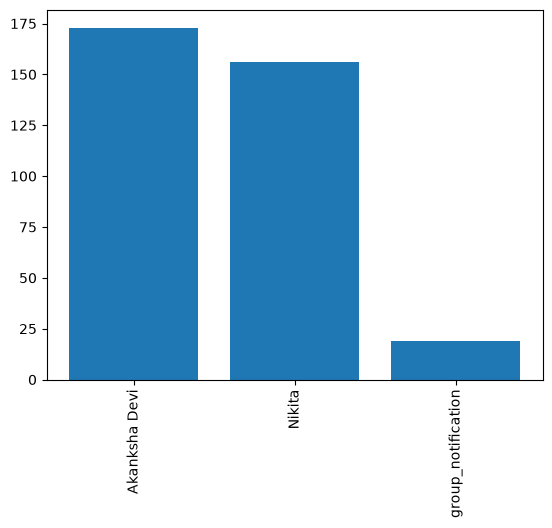

In [29]:
plt.bar(name,count);
plt.xticks(rotation='vertical')
plt.show

In [30]:
round((df['user'].value_counts()/df.shape[0])*100,2).reset_index().rename(columns={'index':'name','user':'percent'})





,percent,count
0,Akanksha Devi,49.71
1,Nikita,44.83
2,group_notification,5.46


In [31]:
x

user
Akanksha Devi         173
Nikita                156
group_notification     19
Name: count, dtype: int64

In [34]:
temp=df[df['user']!='group_notification']
temp

,date,user,message,year,month,day,hour,minute
1,2026-07-11 12:50:00,Nikita,<Media omitted>,2026,July,11,12,50
2,2026-07-11 12:50:00,Akanksha Devi,Thanks,2026,July,11,12,50
3,2026-07-11 12:50:00,Nikita,Welciii,2026,July,11,12,50
4,2026-07-13 12:52:00,Akanksha Devi,Arey did you ask Di to be in our group ?,2026,July,13,12,52
5,2026-07-13 12:52:00,Nikita,Yes,2026,July,13,12,52
...,...,...,...,...,...,...,...,...
343,2026-10-10 11:08:00,Nikita,Sunnnnn,2026,October,10,11,8
344,2026-10-10 11:08:00,Nikita,Aaj jaldi aana class,2026,October,10,11,8
345,2026-10-10 12:12:00,Akanksha Devi,Okayh,2026,October,10,12,12
346,2026-10-11 13:04:00,Akanksha Devi,😂,2026,October,11,13,4


In [36]:
temp=temp[temp['message']!='<Media omitted>']
temp

,date,user,message,year,month,day,hour,minute
2,2026-07-11 12:50:00,Akanksha Devi,Thanks,2026,July,11,12,50
3,2026-07-11 12:50:00,Nikita,Welciii,2026,July,11,12,50
4,2026-07-13 12:52:00,Akanksha Devi,Arey did you ask Di to be in our group ?,2026,July,13,12,52
5,2026-07-13 12:52:00,Nikita,Yes,2026,July,13,12,52
6,2026-07-13 23:09:00,Akanksha Devi,"Bhai, woh solid works ka konsa version downloa...",2026,July,13,23,9
...,...,...,...,...,...,...,...,...
343,2026-10-10 11:08:00,Nikita,Sunnnnn,2026,October,10,11,8
344,2026-10-10 11:08:00,Nikita,Aaj jaldi aana class,2026,October,10,11,8
345,2026-10-10 12:12:00,Akanksha Devi,Okayh,2026,October,10,12,12
346,2026-10-11 13:04:00,Akanksha Devi,😂,2026,October,11,13,4


In [37]:
f=open('stop_hinglish.txt','r')
stop_words=f.read()
print(stop_words)

.
..
...
?
-
--
1
2
3
4
5
6
7
8
9
0
a
aadi
aaj
aap
aapne
aata
aati
aaya
aaye
ab
abbe
abbey
abe
abhi
able
about
above
accha
according
accordingly
acha
achcha
across
actually
after
afterwards
again
against
agar
ain
aint
ain't
aisa
aise
aisi
alag
all
allow
allows
almost
alone
along
already
also
although
always
am
among
amongst
an
and
andar
another
any
anybody
anyhow
anyone
anything
anyway
anyways
anywhere
ap
apan
apart
apna
apnaa
apne
apni
appear
are
aren
arent
aren't
around
arre
as
aside
ask
asking
at
aur
avum
aya
aye
baad
baar
bad
bahut
bana
banae
banai
banao
banaya
banaye
banayi
banda
bande
bandi
bane
bani
bas
bata
batao
bc
be
became
because
become
becomes
becoming
been
before
beforehand
behind
being
below
beside
besides
best
better
between
beyond
bhai
bheetar
bhi
bhitar
bht
bilkul
bohot
bol
bola
bole
boli
bolo
bolta
bolte
bolti
both
brief
bro
btw
but
by
came
can
cannot
cant
can't
cause
causes
certain
certainly
chahiye
chaiye
chal
chalega
chhaiye
clearly
c'mon
com
come
comes
could
coul

In [42]:
words=[]
for message in temp['message']:
    for word in message.lower().split():
        if word not in stop_words:
            words.append(word)

In [43]:
from collections import Counter
pd.DataFrame(Counter(words).most_common(20))

,0,1
0,hn,11
1,call,9
2,aaur,8
3,bhaiya,7
4,",",7
5,?!,7
6,ohh,6
7,achaa,5
8,jaldi,5
9,bhaii,5
